In [1]:

# ============================================================
# 1. DATA MANIPULATION & VISUALIZATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# 2. SYSTEM & MODEL SAVING
# ============================================================

import sys
import joblib
import sklearn


# ============================================================
# 3. STATISTICAL ANALYSIS & GEOMETRY
# ============================================================

from scipy.stats import mode, chi2_contingency
from scipy.spatial import ConvexHull


# ============================================================
# 4. PREPROCESSING
# ============================================================

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    LabelEncoder
)


# ============================================================
# 5. DIMENSIONALITY REDUCTION
# ============================================================

from sklearn.decomposition import PCA


# ============================================================
# 6. CLUSTERING ALGORITHMS
# ============================================================

from sklearn.cluster import (
    KMeans,
    DBSCAN,
    AgglomerativeClustering,
    Birch
)

from sklearn.mixture import GaussianMixture


# ============================================================
# 7. CLUSTERING EVALUATION
# ============================================================

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)


# ============================================================
# 8. CLUSTERING VISUALIZATION
# ============================================================

from yellowbrick.cluster import KElbowVisualizer


# ============================================================
# 9. VERSION INFORMATION
# ============================================================

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

Python: 3.13.18
scikit-learn: 1.6.1
NumPy: 2.4.6
pandas: 2.2.3


## **Collect Initial Data**

In [2]:
url = 'https://drive.google.com/uc?export=download&id=1wDUGsptazQkEFKgFichW_W9NNsJTAPLN' # Dataset hasil proses 04_NHANES_Pola_Makan_&_Diabetes_2017_2018_Fixing_Dataset

In [3]:
df = pd.read_csv(url)
df.to_csv("data.csv", index=False)

In [4]:
df = pd.read_csv("data.csv")

In [5]:
df.head()

,SEQN,RIDAGEYR,RIAGENDR,milk_dairy,meat_poultry_fish,eggs,legumes_nuts_seeds,grain_products,fruits_and_juices,vegetables,fats_oils_dressings,sugars_sweets_beverages,BMI,LBDGLUSI,BPXSY,BPXDI,Status_Diabetes
0,93708,66.0,2.0,18.554380,23.713564,0.000000,2.452594,28.616737,5.039577,15.874669,1.179261,4.569217,23.7,6.77,134.934034,74.742192,Prediabetes
1,93711,56.0,1.0,9.759792,0.000000,1.510079,3.166938,8.723122,6.908612,16.262645,0.000000,53.668812,21.3,5.94,101.333333,66.666667,Prediabetes
2,93717,22.0,1.0,5.955269,16.839036,0.000000,0.000000,21.536511,2.406493,13.208375,1.617163,38.437153,24.5,5.05,118.666667,65.333333,Normal
3,93719,13.0,2.0,1.368908,11.458734,0.000000,0.444243,20.717764,29.963431,5.690418,0.912605,29.443898,26.0,4.77,101.333333,64.000000,Normal
4,93721,60.0,2.0,10.398765,6.952969,3.956000,2.217757,7.208071,7.816096,18.940847,0.000000,42.509494,35.9,5.77,136.000000,67.333333,Prediabetes


In [6]:
df.describe()[['RIDAGEYR', 'RIAGENDR', 'BMI','BPXSY', 'BPXDI', 'LBDGLUSI']].T

,count,mean,std,min,25%,50%,75%,max
RIDAGEYR,2324.0,45.395009,20.654668,12.000000,26.00,47.000000,62.000000,80.000000
RIAGENDR,2324.0,1.526248,0.499418,1.000000,1.00,2.000000,2.000000,2.000000
BMI,2324.0,28.933662,6.983649,14.600000,23.90,28.000000,33.025000,46.712500
BPXSY,2324.0,122.493525,16.679677,87.333333,110.00,120.666667,132.367192,163.333333
BPXDI,2324.0,70.677150,10.679783,44.000000,64.00,70.516364,77.333333,97.333333
LBDGLUSI,2324.0,6.188739,1.930994,2.610000,5.33,5.660000,6.220000,23.400000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2324 entries, 0 to 2323
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   SEQN                     2324 non-null   int64  
 1   RIDAGEYR                 2324 non-null   float64
 2   RIAGENDR                 2324 non-null   float64
 3   milk_dairy               2324 non-null   float64
 4   meat_poultry_fish        2324 non-null   float64
 5   eggs                     2324 non-null   float64
 6   legumes_nuts_seeds       2324 non-null   float64
 7   grain_products           2324 non-null   float64
 8   fruits_and_juices        2324 non-null   float64
 9   vegetables               2324 non-null   float64
 10  fats_oils_dressings      2324 non-null   float64
 11  sugars_sweets_beverages  2324 non-null   float64
 12  BMI                      2324 non-null   float64
 13  LBDGLUSI                 2324 non-null   float64
 14  BPXSY                   

# **Membangun Model Clustering**

## **Memilih Kolom Fitur**

In [8]:
kolom_pangan = [
    'milk_dairy',
    'meat_poultry_fish',
    'eggs',
    'legumes_nuts_seeds',
    'grain_products',
    'fruits_and_juices',
    'vegetables',
    'fats_oils_dressings',
    'sugars_sweets_beverages'
]

semua_kolom = [
    'milk_dairy',
    'meat_poultry_fish',
    'eggs',
    'legumes_nuts_seeds',
    'grain_products',
    'fruits_and_juices',
    'vegetables',
    'fats_oils_dressings',
    'sugars_sweets_beverages',
    'BMI',
    'BPXSY',
    'BPXDI',
    'LBDGLUSI'
]

kolom_health = [
    'RIDAGEYR',
    'RIAGENDR',
    'BMI',
    'BPXSY',
    'BPXDI',
    'LBDGLUSI'
]

df_clustering = df[kolom_pangan].copy()

In [9]:
x = df_clustering[kolom_pangan]

### **Menggunakan PCA untuk membuat visualisasi cluster saja**

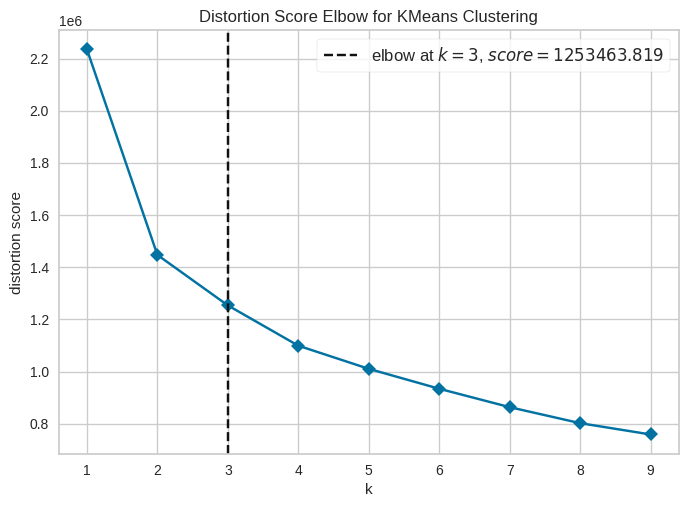

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [10]:
kmeans = KMeans(
    random_state=42,
    n_init=10
)

visualizer = KElbowVisualizer(
    kmeans,
    k=(1, 10),
    timings=False
)

visualizer.fit(x)
visualizer.show()

## **Membandingkan Model Kmeans, Agglomerative, dan GMM**

In [11]:
def evaluasi_clustering(x, nama_percobaan):
    hasil = []

    for k in range(2, 11):
        models = {
            'K-Means': KMeans(n_clusters=k, random_state=42, n_init=10),
            'Agglomerative': AgglomerativeClustering(n_clusters=k),
            'GMM': GaussianMixture(n_components=k, random_state=42)
        }

        for nama, model in models.items():
            labels = model.fit_predict(x)

            hasil.append([
                k, nama,
                silhouette_score(x, labels),
                davies_bouldin_score(x, labels),
                calinski_harabasz_score(x, labels)
            ])

    return pd.DataFrame(
        hasil,
        columns=[
            'K', 'Model',
            'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz'
        ]
    )

hasil_1 = evaluasi_clustering(x, 'Pola Makan')

## **Analisis Sensitivitas Representasi Fitur**

In [12]:
# 1. Cetak Mean dan SD aktual ke-9 kelompok pangan
stats_9 = pd.DataFrame({
    'Mean': x.mean().round(4),
    'SD': x.std().round(4)
}).sort_values('SD', ascending=False)
print("=== MEAN DAN SD 9 KELOMPOK PANGAN ===")
print(stats_9)

# 2. Uji Sensitivitas Representasi Fitur
# Ganti angka k_utama dan model di bawah sesuai model & K terbaik yang Anda pilih di naskah
k_utama = 3

labels_raw = KMeans(n_clusters=k_utama, random_state=42, n_init=10).fit_predict(x)

# Alternatif A: Standardisasi Z-score
x_z = StandardScaler().fit_transform(x)
labels_z = KMeans(n_clusters=k_utama, random_state=42, n_init=10).fit_predict(x_z)

# Alternatif B: Transformasi akar kuadrat / Hellinger (cocok untuk data proporsi banyak nol)
x_sqrt = np.sqrt(x)
labels_sqrt = KMeans(n_clusters=k_utama, random_state=42, n_init=10).fit_predict(x_sqrt)

print("\n=== TINGKAT KESESUAIAN KLASTER (ARI & NMI) ===")
print(f"Raw vs Z-score   -> ARI: {adjusted_rand_score(labels_raw, labels_z):.4f}, NMI: {normalized_mutual_info_score(labels_raw, labels_z):.4f}")
print(f"Raw vs Sqrt/Hell -> ARI: {adjusted_rand_score(labels_raw, labels_sqrt):.4f}, NMI: {normalized_mutual_info_score(labels_raw, labels_sqrt):.4f}")

print("\n=== PROFIL RATA-RATA KLASTER: PROPORSI MENTAH (RAW) ===")
print(pd.DataFrame(x).groupby(labels_raw).mean().round(3))

print("\n=== PROFIL RATA-RATA KLASTER: SQRT / HELLINGER ===")
print(pd.DataFrame(x).groupby(labels_sqrt).mean().round(3))

print("\n=== PROFIL RATA-RATA KLASTER: Z-SCORE ===")
print(pd.DataFrame(x).groupby(labels_z).mean().round(3))

=== MEAN DAN SD 9 KELOMPOK PANGAN ===
                            Mean       SD
sugars_sweets_beverages  39.2938  20.4832
grain_products           18.8109  12.9556
fruits_and_juices         8.2020   9.9582
milk_dairy                9.0851   9.7479
meat_poultry_fish        11.4685   9.0248
vegetables                8.7773   8.5770
legumes_nuts_seeds        1.8340   3.8780
eggs                      1.6551   2.9697
fats_oils_dressings       0.8733   1.2549

=== TINGKAT KESESUAIAN KLASTER (ARI & NMI) ===
Raw vs Z-score   -> ARI: 0.3142, NMI: 0.3725
Raw vs Sqrt/Hell -> ARI: 0.3288, NMI: 0.3751

=== PROFIL RATA-RATA KLASTER: PROPORSI MENTAH (RAW) ===
   milk_dairy  meat_poultry_fish   eggs  legumes_nuts_seeds  grain_products  \
0       9.716             12.935  1.830               1.948          17.780   
1       4.794              8.877  1.229               1.072          12.109   
2      13.561             12.346  1.910               2.626          29.195   

   fruits_and_juices  vegetabl

In [13]:
def highlight_best(df):

    styles = pd.DataFrame(
        '',
        index=df.index,
        columns=df.columns
    )

    warna = {
        'K-Means': 'lightblue',
        'Agglomerative': 'lightgreen',
        'GMM': 'lightcoral'
    }

    for model in df['Model'].unique():

        idx = df[df['Model'] == model].index
        color = warna[model]

        # Silhouette → tertinggi
        best_silhouette = df.loc[idx, 'Silhouette'].idxmax()
        styles.loc[best_silhouette, 'Silhouette'] = (
            f'background-color: {color}; font-weight: bold'
        )

        # Davies-Bouldin → terendah
        best_db = df.loc[idx, 'Davies-Bouldin'].idxmin()
        styles.loc[best_db, 'Davies-Bouldin'] = (
            f'background-color: {color}; font-weight: bold'
        )

        # Calinski-Harabasz → tertinggi
        best_ch = df.loc[idx, 'Calinski-Harabasz'].idxmax()
        styles.loc[best_ch, 'Calinski-Harabasz'] = (
            f'background-color: {color}; font-weight: bold'
        )

    return styles


def tampilkan_hasil(df, nama):

    display(
        df.style
        .apply(highlight_best, axis=None)
        .format({
            'Silhouette': '{:.2f}',
            'Davies-Bouldin': '{:.2f}',
            'Calinski-Harabasz': '{:.2f}'
        })
    )


tampilkan_hasil(hasil_1, 'Pola Makan')

,K,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,K-Means,0.30,1.25,1264.33
1,2,Agglomerative,0.23,1.14,923.97
2,2,GMM,0.01,8.28,27.83
3,3,K-Means,0.21,1.68,908.57
4,3,Agglomerative,0.17,1.76,790.66
5,3,GMM,-0.03,9.77,47.98
6,4,K-Means,0.20,1.56,799.23
7,4,Agglomerative,0.17,1.73,664.03
8,4,GMM,-0.07,8.74,36.54
9,5,K-Means,0.20,1.56,702.73


## **Grafik Performa Model**

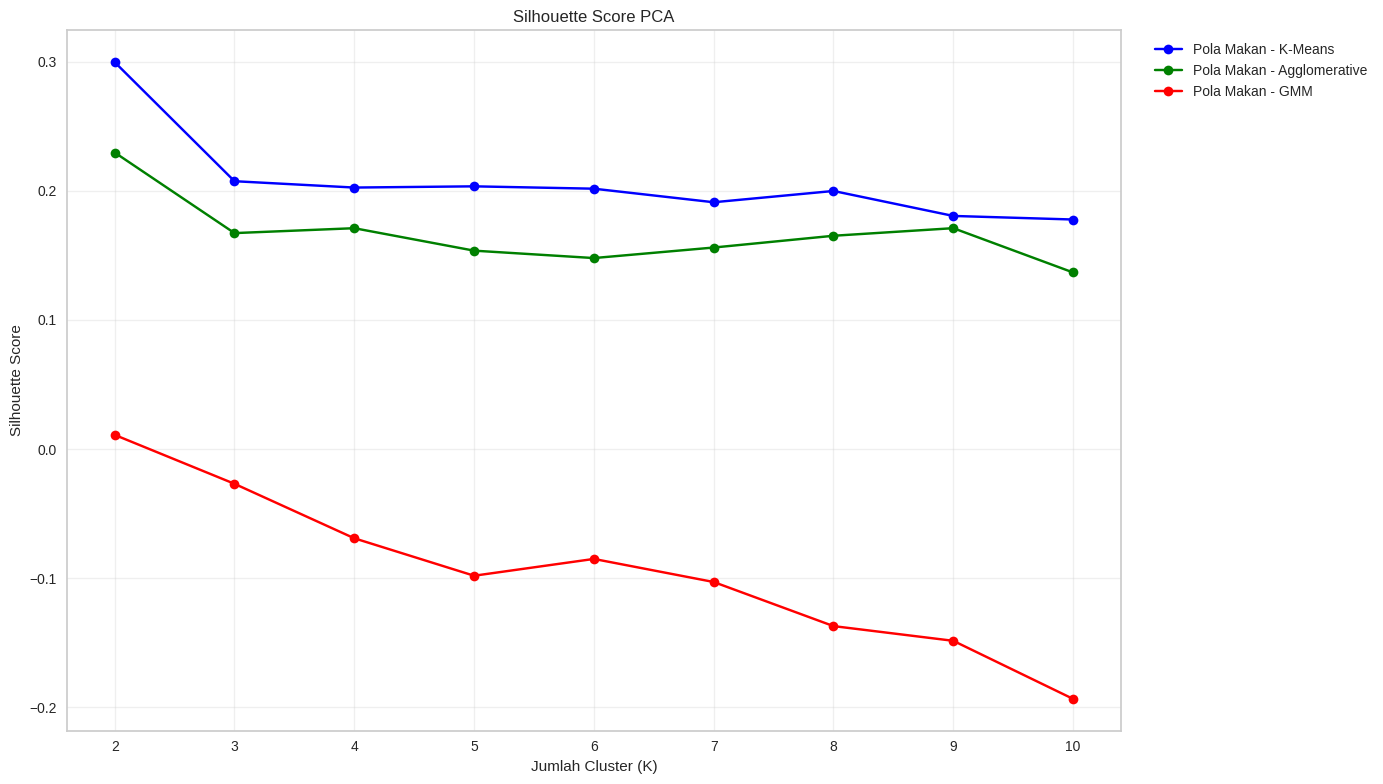

In [14]:
hasil_list = [hasil_1]

warna_model = {
    'K-Means': 'blue',
    'Agglomerative': 'green',
    'GMM': 'red'
}

gaya_percobaan = ['-', '--', ':']
nama_percobaan_list = ['Pola Makan']

plt.figure(figsize=(14, 8))

for hasil, gaya, nama_percobaan in zip(hasil_list, gaya_percobaan, nama_percobaan_list):

    for model in hasil['Model'].unique():

        data = hasil[hasil['Model'] == model]

        plt.plot(
            data['K'],
            data['Silhouette'],
            color=warna_model[model],
            linestyle=gaya,
            marker='o',
            label=f'{nama_percobaan} - {model}'
        )

plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score PCA')
plt.xticks(range(2, 11))
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## **Analisis Stabilitas Clustering K-Means**

In [15]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Menggunakan sembilan fitur proporsi makanan
X_9 = df[kolom_pangan].copy()

print("Jumlah data:", X_9.shape[0])
print("Jumlah fitur:", X_9.shape[1])
print("Missing values:", X_9.isna().sum().sum())


def ringkasan_ari(values):
    return {
        "Mean ARI": np.mean(values),
        "SD ARI": np.std(values, ddof=1),
        "Min ARI": np.min(values),
        "Max ARI": np.max(values)
    }


def buat_kmeans(k, seed, n_init):
    return KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=n_init,
        max_iter=300,
        tol=1e-4,
        algorithm="lloyd",
        random_state=seed
    )


# 1. Initialization stability
def uji_inisialisasi(data, k, n_runs=50):

    # Model referensi
    ref_model = buat_kmeans(k, seed=42, n_init=10)
    ref_labels = ref_model.fit_predict(data)

    ari_single = []
    ari_multi = []

    # Menggunakan 50 seed berbeda, tanpa seed referensi
    seeds = [s for s in range(n_runs + 1) if s != 42][:n_runs]

    for seed in seeds:

        # Satu kali inisialisasi
        labels_1 = buat_kmeans(
            k, seed=seed, n_init=1
        ).fit_predict(data)

        ari_single.append(
            adjusted_rand_score(ref_labels, labels_1)
        )

        # Sepuluh kali inisialisasi
        labels_10 = buat_kmeans(
            k, seed=seed, n_init=10
        ).fit_predict(data)

        ari_multi.append(
            adjusted_rand_score(ref_labels, labels_10)
        )

    return (
        ringkasan_ari(ari_single),
        ringkasan_ari(ari_multi)
    )


# 2. Participant subsampling stability
def uji_resampling(data, k, n_runs=100, frac=0.8):

    rng = np.random.default_rng(42)

    # Model referensi dari seluruh dataset
    ref_model = buat_kmeans(k, seed=42, n_init=10)
    ref_labels = ref_model.fit_predict(data)

    n_samples = len(data)
    sub_size = int(n_samples * frac)

    ari_sub = []

    for i in range(n_runs):

        # Mengambil 80% peserta tanpa pengembalian
        idx = rng.choice(
            n_samples,
            size=sub_size,
            replace=False
        )

        # Melatih model pada subsample
        km_sub = buat_kmeans(
            k, seed=i, n_init=10
        )

        km_sub.fit(data.iloc[idx])

        # Memprediksi seluruh peserta
        pred_all = km_sub.predict(data)

        # Membandingkan dengan label referensi
        ari_sub.append(
            adjusted_rand_score(ref_labels, pred_all)
        )

    return ringkasan_ari(ari_sub)


# 3. Menjalankan pengujian untuk K=2 dan K=3
hasil_stabilitas = {}

for k in [2, 3]:

    print(f"\n========== K = {k} ==========")

    init_1, init_10 = uji_inisialisasi(
        X_9, k, n_runs=50
    )

    resampling = uji_resampling(
        X_9, k, n_runs=100, frac=0.8
    )

    hasil_stabilitas[k] = {
        "Init n_init=1": init_1,
        "Init n_init=10": init_10,
        "Participant subsampling 80%": resampling
    }

    print("\n1. Initialization Stability (n_init=1)")
    for key, value in init_1.items():
        print(f"{key}: {value:.4f}")

    print("\n2. Initialization Stability (n_init=10)")
    for key, value in init_10.items():
        print(f"{key}: {value:.4f}")

    print("\n3. Participant Subsampling Stability")
    for key, value in resampling.items():
        print(f"{key}: {value:.4f}")


Jumlah data: 2324
Jumlah fitur: 9
Missing values: 0

========== K = 2 ==========

1. Initialization Stability (n_init=1)
Mean ARI: 0.9951
SD ARI: 0.0036
Min ARI: 0.9914
Max ARI: 1.0000

2. Initialization Stability (n_init=10)
Mean ARI: 0.9992
SD ARI: 0.0014
Min ARI: 0.9931
Max ARI: 1.0000

3. Participant Subsampling Stability
Mean ARI: 0.9863
SD ARI: 0.0121
Min ARI: 0.9273
Max ARI: 1.0000

========== K = 3 ==========

1. Initialization Stability (n_init=1)
Mean ARI: 0.6681
SD ARI: 0.3249
Min ARI: 0.3234
Max ARI: 0.9949

2. Initialization Stability (n_init=10)
Mean ARI: 0.9825
SD ARI: 0.0142
Min ARI: 0.9009
Max ARI: 0.9974

3. Participant Subsampling Stability
Mean ARI: 0.8640
SD ARI: 0.2092
Min ARI: 0.3201
Max ARI: 0.9897


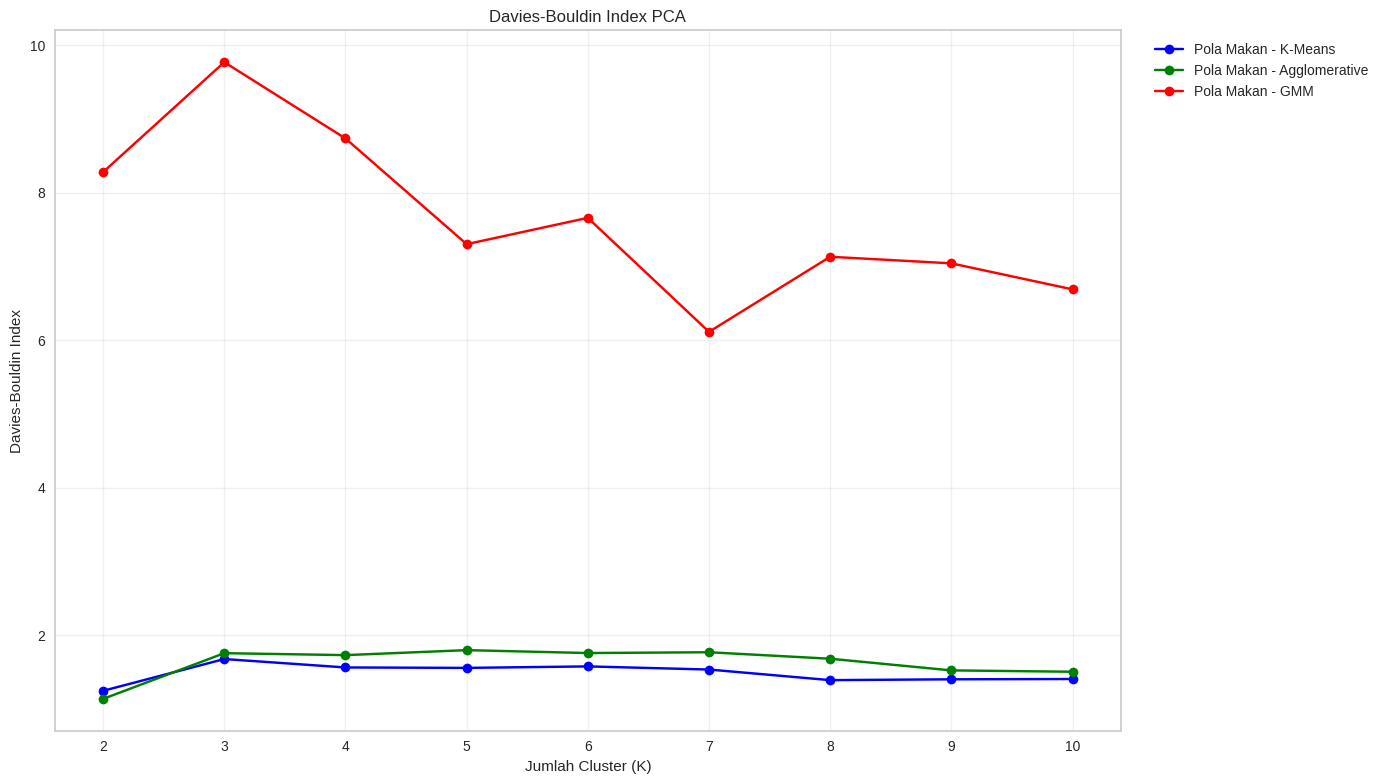

In [16]:
hasil_list = [hasil_1]

warna_model = {
    'K-Means': 'blue',
    'Agglomerative': 'green',
    'GMM': 'red'
}

gaya_percobaan = ['-', '--', ':']
nama_percobaan_list = ['Pola Makan']

plt.figure(figsize=(14, 8))

for hasil, gaya in zip(hasil_list, gaya_percobaan):

    for model in hasil['Model'].unique():

        data = hasil[hasil['Model'] == model]

        plt.plot(
            data['K'],
            data['Davies-Bouldin'],
            color=warna_model[model],
            linestyle=gaya,
            marker='o',
            label=f'{nama_percobaan} - {model}'
        )

plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Davies-Bouldin Index')
plt.title('Davies-Bouldin Index PCA')
plt.xticks(range(2, 11))
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

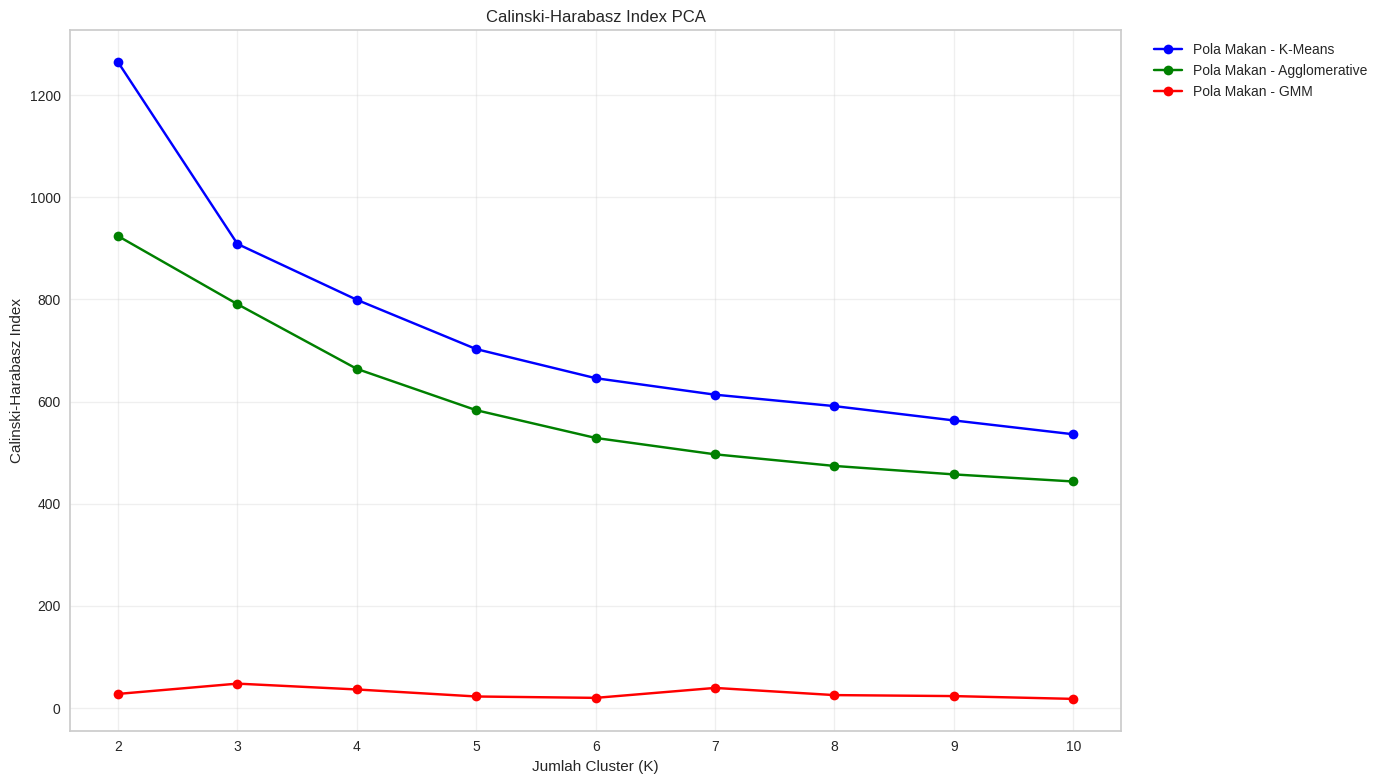

In [17]:
hasil_list = [hasil_1]

warna_model = {
    'K-Means': 'blue',
    'Agglomerative': 'green',
    'GMM': 'red'
}

gaya_percobaan = ['-', '--', ':']
nama_percobaan_list = ['Pola Makan']

plt.figure(figsize=(14, 8))

for hasil, gaya in zip(hasil_list, gaya_percobaan):

    for model in hasil['Model'].unique():

        data = hasil[hasil['Model'] == model]

        plt.plot(
            data['K'],
            data['Calinski-Harabasz'],
            color=warna_model[model],
            linestyle=gaya,
            marker='o',
            label=f'{nama_percobaan} - {model}'
        )

plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Calinski-Harabasz Index')
plt.title('Calinski-Harabasz Index PCA')
plt.xticks(range(2, 11))
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## **Memilih Model Terbaik**

In [18]:
# Menggunakan sembilan fitur makanan yang sama
X_9 = df[kolom_pangan].copy()

# Menyimpan hasil setiap konfigurasi
hasil_cluster = {}

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_9)

    # Simpan model dan label
    hasil_cluster[k] = {
        'model': model,
        'labels': labels,
        'centroid': model.cluster_centers_
    }

    # Hitung profil konsumsi
    profil = (
        X_9.assign(Cluster=labels)
        .groupby('Cluster')[kolom_pangan]
        .mean()
    )

    # Hitung jumlah anggota
    jumlah = pd.Series(labels).value_counts().sort_index()

    print(f"\n========== K = {k} ==========")
    print("Jumlah anggota:")
    print(jumlah)

    print("\nProfil konsumsi:")
    display(profil.round(2).T)



========== K = 2 ==========
Jumlah anggota:
0    1176
1    1148
Name: count, dtype: int64

Profil konsumsi:


Cluster,0,1
milk_dairy,12.22,5.87
meat_poultry_fish,12.83,10.07
eggs,1.85,1.45
legumes_nuts_seeds,2.43,1.22
grain_products,24.18,13.31
fruits_and_juices,12.08,4.23
vegetables,10.67,6.84
fats_oils_dressings,0.92,0.83
sugars_sweets_beverages,22.82,56.17



========== K = 3 ==========
Jumlah anggota:
0    984
1    755
2    585
Name: count, dtype: int64

Profil konsumsi:


Cluster,0,1,2
milk_dairy,9.72,4.79,13.56
meat_poultry_fish,12.94,8.88,12.35
eggs,1.83,1.23,1.91
legumes_nuts_seeds,1.95,1.07,2.63
grain_products,17.78,12.11,29.20
fruits_and_juices,8.48,3.03,14.41
vegetables,9.45,5.78,11.51
fats_oils_dressings,0.93,0.77,0.90
sugars_sweets_beverages,36.93,62.33,13.54


### **Visualisasi Cluster menggunakan PCA**

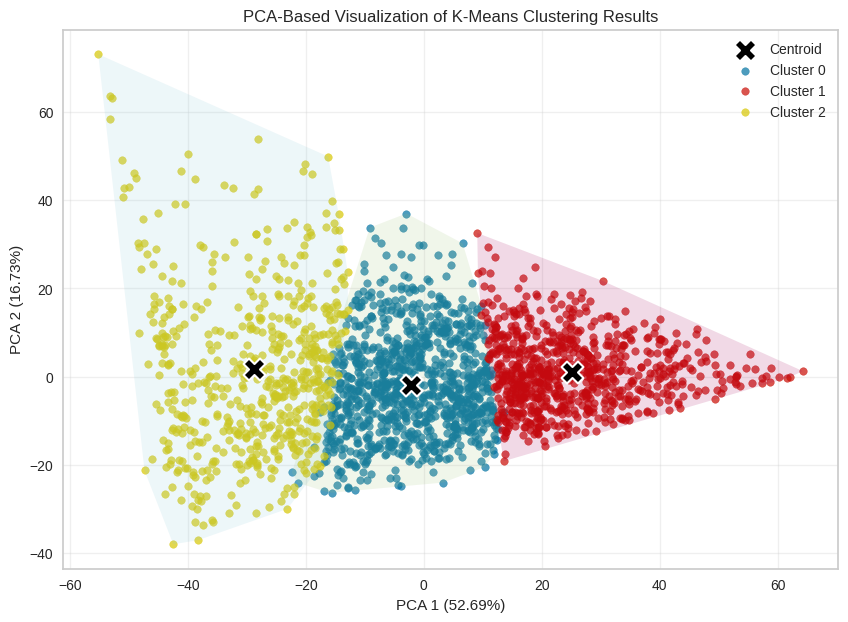

Explained variance: [0.52693752 0.16730721]
Total explained variance: 0.6942447295821393


In [19]:
# Tentukan jumlah cluster terbaik (misalnya K=3)
k_terpilih = 3
kmeans_model = KMeans(n_clusters=k_terpilih, random_state=42, n_init=10)
df['Cluster'] = kmeans_model.fit_predict(df[kolom_pangan])

pca = PCA(n_components=2, random_state=42)
x_pca = pca.fit_transform(df[kolom_pangan])

plt.figure(figsize=(10, 7))

for cluster in sorted(df['Cluster'].unique()):

    mask = df['Cluster'] == cluster
    points = x_pca[mask, :2]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        s=30,
        alpha=0.7,
        label=f'Cluster {cluster}'
    )

    if len(points) >= 3:
        hull = ConvexHull(points)
        hull_points = points[hull.vertices]

        plt.fill(
            hull_points[:, 0],
            hull_points[:, 1],
            alpha=0.15
        )

    centroid = points.mean(axis=0)

    plt.scatter(
        centroid[0],
        centroid[1],
        marker='X',
        s=250,
        c='black',
        edgecolors='white',
        linewidths=1.5,
        zorder=5,
        label='Centroid' if cluster == 0 else None
    )

plt.xlabel(
    f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.2f}%)'
)

plt.ylabel(
    f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.2f}%)'
)

plt.title('PCA-Based Visualization of K-Means Clustering Results')
plt.grid(True, alpha=0.3)

handles, labels = plt.gca().get_legend_handles_labels()

order = [labels.index('Centroid')] + [
    i for i, label in enumerate(labels)
    if label != 'Centroid'
]

plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order]
)

plt.show()

print("Explained variance:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

In [20]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=kolom_pangan,
    columns=['PCA 1', 'PCA 2']
)

print(loadings.round(4))

                          PCA 1   PCA 2
milk_dairy              -0.1622 -0.1448
meat_poultry_fish       -0.0765 -0.2031
eggs                    -0.0123 -0.0228
legumes_nuts_seeds      -0.0283 -0.0236
grain_products          -0.3050  0.8605
fruits_and_juices       -0.2080 -0.3053
vegetables              -0.1088 -0.2879
fats_oils_dressings     -0.0038 -0.0138
sugars_sweets_beverages  0.9049  0.1410


# **Interpretasi Cluster**

## **Jumlah Persentase Tiap CLuster**

In [21]:
cluster_count = df['Cluster'].value_counts().sort_index()

cluster_percent = (
    df['Cluster']
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

hasil_cluster = pd.DataFrame({
    'Jumlah': cluster_count,
    'Persentase': cluster_percent.round(2)
})

display(hasil_cluster)

,Jumlah,Persentase
Cluster,,
0,984,42.34
1,755,32.49
2,585,25.17


## **Profil Tiap Cluster**

In [22]:
profil_cluster = df.copy()
profil_cluster['Cluster'] = df['Cluster']

# Statistik proporsi pangan per cluster
profil_pangan = (
    profil_cluster
    .groupby('Cluster')[semua_kolom]
    .agg(['mean', 'median', 'min', 'max'])
)

display(profil_pangan.round(2).T)

Cluster                              0       1       2
milk_dairy              mean      9.72    4.79   13.56
                        median    7.61    2.77   11.13
                        min       0.00    0.00    0.00
                        max      57.75   29.15   59.69
meat_poultry_fish       mean     12.94    8.88   12.35
                        median   10.94    8.05   10.30
                        min       0.00    0.00    0.00
                        max      68.31   42.52   61.89
eggs                    mean      1.83    1.23    1.91
                        median    0.00    0.00    0.00
                        min       0.00    0.00    0.00
                        max      19.87   14.03   29.92
legumes_nuts_seeds      mean      1.95    1.07    2.63
                        median    0.00    0.00    0.00
                        min       0.00    0.00    0.00
                        max      32.17   20.21   43.84
grain_products          mean     17.78   12.11   29.20
                        median   16.48   11.43   26.53
                        min       0.00    0.00    0.00
                        max      52.49   44.66  100.00
fruits_and_juices       mean      8.48    3.03   14.41
                        median    6.69    0.13   12.07
                        min       0.00    0.00    0.00
                        max      49.84   27.93   80.94
vegetables              mean      9.45    5.78   11.51
                        median    7.66    4.42    8.42
                        min       0.00    0.00    0.00
                        max      43.63   40.37   72.35
fats_oils_dressings     mean      0.93    0.77    0.90
                        median    0.47    0.37    0.21
                        min       0.00    0.00    0.00
                        max       8.20   10.54   10.30
sugars_sweets_beverages mean     36.93   62.33   13.54
                        median   37.24   60.17   14.71
                        min      11.58   47.33    0.00
                        max      51.11   98.69   32.23
BMI                     mean     28.91   29.90   27.73
                        median   28.00   29.10   26.70
                        min      15.10   15.40   14.60
                        max      46.71   46.71   46.71
BPXSY                   mean    122.84  124.51  119.31
                        median  121.33  122.67  116.67
                        min      88.00   90.00   87.33
                        max     163.33  163.33  163.33
BPXDI                   mean     70.55   72.24   68.88
                        median   70.52   72.00   69.33
                        min      44.00   44.00   44.00
                        max      97.33   97.33   97.33
LBDGLUSI                mean      6.24    6.28    5.98
                        median    5.66    5.77    5.61
                        min       2.94    2.61    3.44
                        max      23.40   21.10   19.30

In [23]:
profil_cluster = df.copy()
profil_cluster['Cluster'] = df['Cluster']

# Statistik proporsi pangan per cluster
profil_pangan = (
    profil_cluster
    .groupby('Cluster')[kolom_pangan]
    .agg(['mean'])
)

display(profil_pangan.round(2).T)

,Cluster,0,1,2
milk_dairy,mean,9.72,4.79,13.56
meat_poultry_fish,mean,12.94,8.88,12.35
eggs,mean,1.83,1.23,1.91
legumes_nuts_seeds,mean,1.95,1.07,2.63
grain_products,mean,17.78,12.11,29.20
fruits_and_juices,mean,8.48,3.03,14.41
vegetables,mean,9.45,5.78,11.51
fats_oils_dressings,mean,0.93,0.77,0.90
sugars_sweets_beverages,mean,36.93,62.33,13.54


In [24]:
profil_cluster = df.copy()
profil_cluster['Cluster'] = df['Cluster']

# Statistik proporsi pangan per cluster
profil_pangan = (
    profil_cluster
    .groupby('Cluster')[kolom_health]
    .agg(['mean', 'min', 'max', 'std'])
)

display(profil_pangan.round(2).T)

Cluster             0       1       2
RIDAGEYR mean   47.69   48.68   37.30
         min    12.00   12.00   12.00
         max    80.00   80.00   80.00
         std    20.63   18.48   21.25
RIAGENDR mean    1.54    1.48    1.57
         min     1.00    1.00    1.00
         max     2.00    2.00    2.00
         std     0.50    0.50    0.50
BMI      mean   28.91   29.90   27.73
         min    15.10   15.40   14.60
         max    46.71   46.71   46.71
         std     6.86    7.07    6.90
BPXSY    mean  122.84  124.51  119.31
         min    88.00   90.00   87.33
         max   163.33  163.33  163.33
         std    16.75   16.54   16.29
BPXDI    mean   70.55   72.24   68.88
         min    44.00   44.00   44.00
         max    97.33   97.33   97.33
         std    10.48   10.57   10.86
LBDGLUSI mean    6.24    6.28    5.98
         min     2.94    2.61    3.44
         max    23.40   21.10   19.30
         std     1.99    2.03    1.66

## **Status Diabetes Berdasarkan Tiap Cluster**

In [25]:
tabel_diabetes = pd.crosstab(
    df['Cluster'],
    df['Status_Diabetes'],
    normalize='index'
) * 100

display(tabel_diabetes.round(2))

Status_Diabetes,Diabetes,Normal,Prediabetes
Cluster,,,
0,15.04,42.68,42.28
1,13.91,40.93,45.17
2,10.43,49.74,39.83


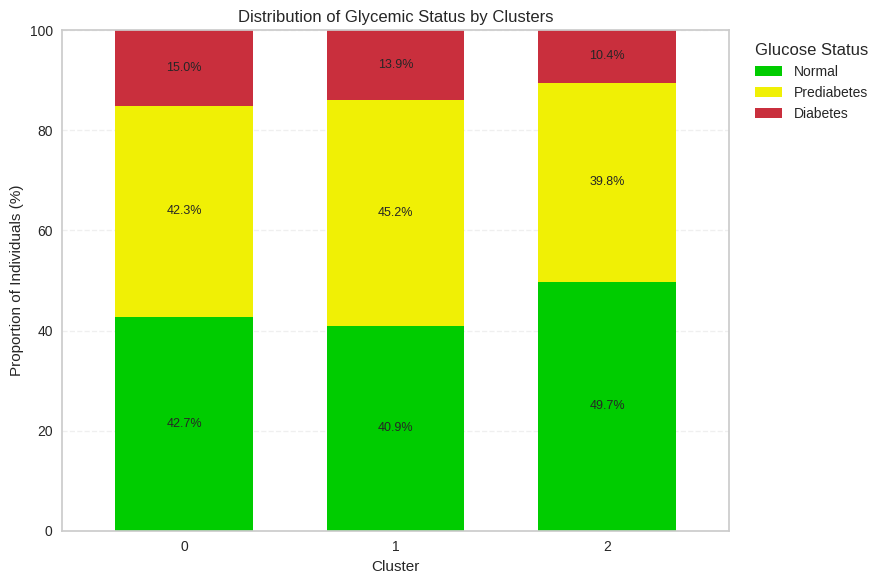

In [26]:
import matplotlib.pyplot as plt

# Membuat tabel distribusi status diabetes dalam persentase
tabel_diabetes = pd.crosstab(
    df['Cluster'],
    df['Status_Diabetes'],
    normalize='index'
) * 100

# Mengatur urutan kategori pada legenda (jika tersedia)
urutan_status = ['Normal', 'Prediabetes', 'Diabetes']
warna = [
    '#00CC00',  # Hijau lebih gelap
    '#f0f005',  # Kuning keemasan
    '#C92F3D'   # Merah sedikit lebih gelap
]

kolom_tersedia = [
    status for status in urutan_status
    if status in tabel_diabetes.columns
]
tabel_diabetes = tabel_diabetes[kolom_tersedia]

# Membuat diagram batang bertumpuk 100%
ax = tabel_diabetes.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 6),
    width=0.65,
    color = warna
)

# Menampilkan persentase pada setiap segmen
for container in ax.containers:
    labels = [
        f'{bar.get_height():.1f}%'
        if bar.get_height() >= 5 else ''
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type='center',
        fontsize=9
    )

ax.set_title('Distribution of Glycemic Status by Clusters')
ax.set_xlabel('Cluster')
ax.set_ylabel('Proportion of Individuals (%)')
ax.set_ylim(0, 100)
ax.legend(title='Glucose Status', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

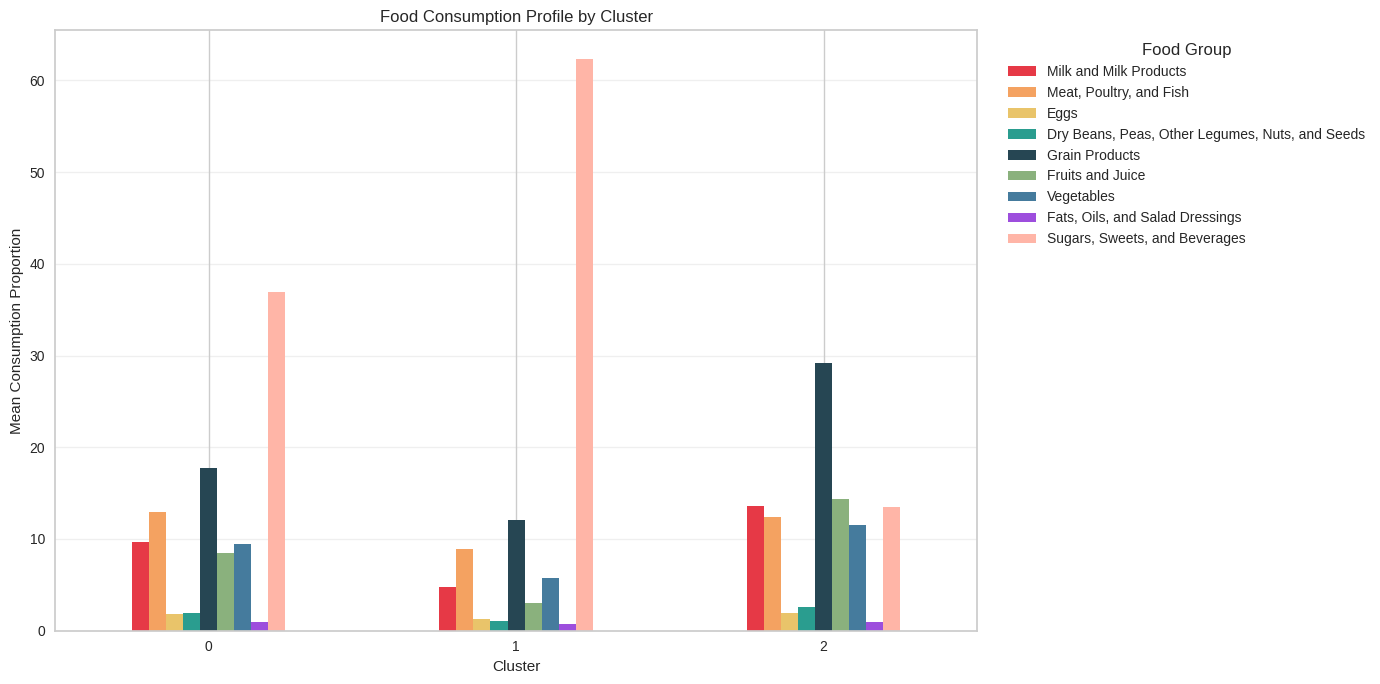

In [27]:
kolom_pangan = [
    'milk_dairy',
    'meat_poultry_fish',
    'eggs',
    'legumes_nuts_seeds',
    'grain_products',
    'fruits_and_juices',
    'vegetables',
    'fats_oils_dressings',
    'sugars_sweets_beverages'
]

# Rata-rata konsumsi setiap pangan berdasarkan cluster
profil_cluster = (
    df.groupby('Cluster')[kolom_pangan]
    .mean()
)

# Ubah nama kolom agar lebih mudah dibaca
nama_pangan = {
    'milk_dairy': 'Milk and Milk Products',
    'meat_poultry_fish': 'Meat, Poultry, and Fish',
    'eggs': 'Eggs',
    'legumes_nuts_seeds': 'Dry Beans, Peas, Other Legumes, Nuts, and Seeds',
    'grain_products': 'Grain Products',
    'fruits_and_juices': 'Fruits and Juice',
    'vegetables': 'Vegetables',
    'fats_oils_dressings': 'Fats, Oils, and Salad Dressings',
    'sugars_sweets_beverages': 'Sugars, Sweets, and Beverages'
}

warna_pangan = [
    '#E63946', # Merah untuk Susu
    '#F4A261', # Oranye untuk Daging/unggas/ikan
    '#E9C46A', # Kuning untuk Telur
    '#2A9D8F', # Hijau tosca untuk Kacang/biji
    '#264653', # Biru gelap untuk Biji-bijian
    '#8AB17D', # Hijau daun untuk Buah
    '#457B9D', # Biru redup untuk Sayuran
    '#9D4EDD', # Ungu untuk Lemak/minyak
    '#FFB5A7'  # Pink pastel untuk Gula/minuman
]

profil_cluster = profil_cluster.rename(columns=nama_pangan)

# Plot
ax = profil_cluster.plot(
    kind='bar',
    figsize=(14, 7),
    color=warna_pangan
)

plt.title('Food Consumption Profile by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Mean Consumption Proportion')
plt.xticks(rotation=0)
plt.legend(
    title='Food Group',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
from sklearn.cluster import KMeans
import pandas as pd

# Menggunakan sembilan fitur makanan
X_9 = df[kolom_pangan].copy()

# Model K=2
model_k2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

label_k2 = model_k2.fit_predict(X_9)

# Model K=3
model_k3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

label_k3 = model_k3.fit_predict(X_9)

# Membuat tabel keanggotaan peserta
perbandingan_cluster = pd.DataFrame({
    "Cluster_K2": label_k2,
    "Cluster_K3": label_k3
})

# Membuat tabel silang
tabel_perubahan = pd.crosstab(
    perbandingan_cluster["Cluster_K2"],
    perbandingan_cluster["Cluster_K3"],
    margins=True
)

print(tabel_perubahan)


Cluster_K3    0    1    2   All
Cluster_K2                     
0           591    0  585  1176
1           393  755    0  1148
All         984  755  585  2324


In [29]:
# Distribusi gender berdasarkan cluster
gender_count = pd.crosstab(
    df['Cluster'],
    df['RIAGENDR']
)

gender_percent = (
    pd.crosstab(
        df['Cluster'],
        df['RIAGENDR'],
        normalize='index'
    ) * 100
)

# Mengubah kode gender menjadi label
gender_count.columns = ['Male', 'Female']
gender_percent.columns = ['Male', 'Female']

print("Jumlah Gender:")
display(gender_count)

print("Persentase Gender (%):")
display(gender_percent.round(2))


Jumlah Gender:


,Male,Female
Cluster,,
0,457,527
1,392,363
2,252,333


Persentase Gender (%):


,Male,Female
Cluster,,
0,46.44,53.56
1,51.92,48.08
2,43.08,56.92


In [30]:
# Jumlah partisipan berdasarkan cluster dan status diabetes
glycemic_count = pd.crosstab(
    df['Cluster'],
    df['Status_Diabetes']
)

# Persentase dalam setiap cluster
glycemic_percent = pd.crosstab(
    df['Cluster'],
    df['Status_Diabetes'],
    normalize='index'
) * 100

print("Jumlah Partisipan:")
display(glycemic_count)

print("Persentase Partisipan (%):")
display(glycemic_percent.round(2))

# Format gabungan n (%)
glycemic_table = glycemic_count.astype(str) + " (" + (
    glycemic_percent.round(2).astype(str) + "%"
    + ")"
)

display(glycemic_table)


Jumlah Partisipan:


Status_Diabetes,Diabetes,Normal,Prediabetes
Cluster,,,
0,148,420,416
1,105,309,341
2,61,291,233


Persentase Partisipan (%):


Status_Diabetes,Diabetes,Normal,Prediabetes
Cluster,,,
0,15.04,42.68,42.28
1,13.91,40.93,45.17
2,10.43,49.74,39.83


Status_Diabetes,Diabetes,Normal,Prediabetes
Cluster,,,
0,148 (15.04%),420 (42.68%),416 (42.28%)
1,105 (13.91%),309 (40.93%),341 (45.17%)
2,61 (10.43%),291 (49.74%),233 (39.83%)
